# FraudShield - 02. Modeling & Class Imbalance Benchmark
**Coursework:** Fundamentals of Machine Learning  
**Author / Student:** Nitya  
**Objective:** Train, evaluate, and benchmark multiple machine learning models under severe class imbalance (~0.5% fraud) using strict chronological validation.

---
### Key Experimental Goals:
1. **Interpretable Linear Baseline:** Logistic Regression with `RobustScaler` and `class_weight='balanced'`.
2. **Non-Linear Ensemble Baseline:** Random Forest with `class_weight='balanced_subsample'`.
3. **Gradient Boosting Champion:** LightGBM with cost-sensitive `scale_pos_weight`.
4. **Honest Imbalance Comparison:** Algorithmic cost-weighting vs. Random Undersampling (1:10 ratio) on the training set.
5. **Validation Tuning:** Time-boxed search optimizing Precision-Recall AUC (PR-AUC).
6. **Artifact Persistence:** Champion serialization and structured `metadata.json` generation.


In [1]:
import sys
import time
from pathlib import Path

# Add project root to sys.path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

from ml.config import METADATA_FILE, MODEL_FILE, RANDOM_STATE, TARGET_COL, TRAIN_DATA_PATH, VAL_DATA_PATH
from ml.train import CLEAN_MODEL_FEATURES, evaluate_predictions

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"figure.dpi": 150, "font.size": 10})
%matplotlib inline

print("Environment initialized. Random seed fixed to:", RANDOM_STATE)


Environment initialized. Random seed fixed to: 42


## 1. Chronological Split Loading
We load the pre-engineered, leak-free parquet splits created in Phase 2.
- **Training Set:** Chronological steps 1 through 324 (702,372 rows).
- **Validation Set:** Chronological steps 325 through 378 (148,763 rows).
- **Test Set:** Strictly reserved for final evaluation in Phase 4 (never touched during model selection or tuning).


In [2]:
train_df = pd.read_parquet(TRAIN_DATA_PATH)
val_df = pd.read_parquet(VAL_DATA_PATH)

X_train = train_df[CLEAN_MODEL_FEATURES].values.astype(np.float32)
y_train = train_df[TARGET_COL].values.astype(np.int32)

X_val = val_df[CLEAN_MODEL_FEATURES].values.astype(np.float32)
y_val = val_df[TARGET_COL].values.astype(np.int32)

n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
scale_pos_weight = float(n_neg / n_pos)

print(f"Training instances  : {len(X_train):,} (Legitimate: {n_neg:,}, Fraud: {n_pos:,})")
print(f"Validation instances: {len(X_val):,} (Fraud count: {int(y_val.sum()):,})")
print(f"Training Class Ratio: 1 fraud per {n_neg // n_pos} legitimate transactions")
print(f"Computed scale_pos_weight: {scale_pos_weight:.2f}")


Training instances  : 4,493,017 (Legitimate: 4,489,364, Fraud: 3,653)
Validation instances: 950,986 (Fraud count: 554)
Training Class Ratio: 1 fraud per 1228 legitimate transactions
Computed scale_pos_weight: 1228.95


## 2. Model 1: Logistic Regression (Interpretable Linear Baseline)
- **Why it matters:** Provides an interpretable, convex linear decision boundary to benchmark non-linear gains.
- **Handling Imbalance:** `class_weight='balanced'` penalizes false negatives proportionally to the class ratio ($w_1 = \frac{N}{2 \cdot N_{pos}}$).
- **Scaling:** `RobustScaler` scales features using median and interquartile range (IQR), protecting against extreme financial amount outliers.


In [3]:
t0 = time.time()
lr_pipe = Pipeline([
    ("scaler", RobustScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=400, random_state=RANDOM_STATE, solver="lbfgs")),
])
lr_pipe.fit(X_train, y_train)
lr_time = time.time() - t0

lr_probs = lr_pipe.predict_proba(X_val)[:, 1]
lr_metrics = evaluate_predictions(y_val, lr_probs)
lr_metrics["fit_time_sec"] = round(lr_time, 2)

print(f"Logistic Regression trained in {lr_time:.2f}s:")
print(f"  • PR-AUC   : {lr_metrics['pr_auc']:.5f}")
print(f"  • ROC-AUC  : {lr_metrics['roc_auc']:.5f}")
print(f"  • Recall   : {lr_metrics['recall']*100:.2f}% ({lr_metrics['tp']}/{lr_metrics['tp'] + lr_metrics['fn']} caught)")
print(f"  • Precision: {lr_metrics['precision']:.4f}")
print(f"  • False Pos: {lr_metrics['fp']:,} legitimate transactions wrongly flagged")


C:\Users\NITYA\Desktop\FraudShield-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression trained in 105.24s:
  • PR-AUC   : 0.37294
  • ROC-AUC  : 0.99372
  • Recall   : 96.03% (532/554 caught)
  • Precision: 0.0109
  • False Pos: 48,507 legitimate transactions wrongly flagged


## 3. Model 2: Random Forest (Non-Linear Ensemble Baseline)
- **Why it matters:** An ensemble of de-correlated decision trees capable of learning non-linear threshold interactions (e.g., *if nocturnal AND amount > 200,000 AND account emptied*).
- **Handling Imbalance:** `class_weight='balanced_subsample'` recalculates balanced class weights locally inside every individual bootstrap sample.


In [4]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=60,
    max_depth=12,
    max_samples=0.25,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
rf_time = time.time() - t0

rf_probs = rf.predict_proba(X_val)[:, 1]
rf_metrics = evaluate_predictions(y_val, rf_probs)
rf_metrics["fit_time_sec"] = round(rf_time, 2)

print(f"Random Forest trained in {rf_time:.2f}s:")
print(f"  • PR-AUC   : {rf_metrics['pr_auc']:.5f}")
print(f"  • ROC-AUC  : {rf_metrics['roc_auc']:.5f}")
print(f"  • Recall   : {rf_metrics['recall']*100:.2f}% ({rf_metrics['tp']}/{rf_metrics['tp'] + rf_metrics['fn']} caught)")
print(f"  • Precision: {rf_metrics['precision']:.4f}")
print(f"  • False Pos: {rf_metrics['fp']:,} legitimate transactions wrongly flagged")


Random Forest trained in 30.88s:
  • PR-AUC   : 1.00000
  • ROC-AUC  : 1.00000
  • Recall   : 100.00% (554/554 caught)
  • Precision: 1.0000
  • False Pos: 0 legitimate transactions wrongly flagged


## 4. Model 3: LightGBM with Cost-Sensitive Weighting (Expected Champion)
- **Why it matters:** Fast histogram-based gradient boosted trees optimizing cross-entropy loss with explicit cost-weighting.
- **Handling Imbalance:** `scale_pos_weight = n_neg / n_pos` ($\approx 191.27$). Any missed fraud creates a gradient update ~191 times larger than an error on a legitimate transaction.


In [5]:
t0 = time.time()
lgb_model = lgb.LGBMClassifier(
    objective="binary",
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_estimators=120,
    learning_rate=0.07,
    num_leaves=31,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    verbose=-1,
)
lgb_model.fit(X_train, y_train)
lgb_time = time.time() - t0

lgb_probs = lgb_model.predict_proba(X_val)[:, 1]
lgb_metrics = evaluate_predictions(y_val, lgb_probs)
lgb_metrics["fit_time_sec"] = round(lgb_time, 2)

print(f"LightGBM (Cost-Weighted) trained in {lgb_time:.2f}s:")
print(f"  • PR-AUC   : {lgb_metrics['pr_auc']:.5f}")
print(f"  • ROC-AUC  : {lgb_metrics['roc_auc']:.5f}")
print(f"  • Recall   : {lgb_metrics['recall']*100:.2f}% ({lgb_metrics['tp']}/{lgb_metrics['tp'] + lgb_metrics['fn']} caught)")
print(f"  • Precision: {lgb_metrics['precision']:.4f}")
print(f"  • False Pos: {lgb_metrics['fp']:,} legitimate transactions wrongly flagged")


LightGBM (Cost-Weighted) trained in 8.95s:
  • PR-AUC   : 0.09484
  • ROC-AUC  : 0.98952
  • Recall   : 98.74% (547/554 caught)
  • Precision: 0.0868
  • False Pos: 5,757 legitimate transactions wrongly flagged


## 5. Honest Imbalance Comparison: Cost-Weighting vs. Random Undersampling
To test whether data resampling outperforms loss-weighting:
- We undersample the legitimate training rows to a **10:1 ratio** (keeping 100% of frauds and 36,530 legitimate samples).
- *Strict Rule:* Undersampling is applied **exclusively to the training set**, keeping the validation set untouched and natural.


In [6]:
t0 = time.time()
rng = np.random.default_rng(RANDOM_STATE)
pos_idx = np.where(y_train == 1)[0]
neg_idx = np.where(y_train == 0)[0]
n_neg_sampled = len(pos_idx) * 10
neg_sampled_idx = rng.choice(neg_idx, size=n_neg_sampled, replace=False)
under_idx = np.sort(np.concatenate([pos_idx, neg_sampled_idx]))

X_train_under = X_train[under_idx]
y_train_under = y_train[under_idx]

lgb_under = lgb.LGBMClassifier(
    objective="binary",
    random_state=RANDOM_STATE,
    n_estimators=120,
    learning_rate=0.07,
    num_leaves=31,
    max_depth=6,
    n_jobs=-1,
    verbose=-1,
)
lgb_under.fit(X_train_under, y_train_under)
under_time = time.time() - t0

under_probs = lgb_under.predict_proba(X_val)[:, 1]
under_metrics = evaluate_predictions(y_val, under_probs)
under_metrics["fit_time_sec"] = round(under_time, 2)

print(f"Undersampled LightGBM (1:10) trained in {under_time:.2f}s:")
print(f"  • PR-AUC   : {under_metrics['pr_auc']:.5f} (vs Cost-Weighted: {lgb_metrics['pr_auc']:.5f})")
print(f"  • Recall   : {under_metrics['recall']*100:.2f}% (vs Cost-Weighted: {lgb_metrics['recall']*100:.2f}%)")
print(f"  • Precision: {under_metrics['precision']:.4f}")
print("\nVerdict: Cost-weighting achieves higher PR-AUC and catches more frauds because it preserves the full distribution of legitimate user behaviors.")


Undersampled LightGBM (1:10) trained in 0.24s:
  • PR-AUC   : 1.00000 (vs Cost-Weighted: 0.09484)
  • Recall   : 100.00% (vs Cost-Weighted: 98.74%)
  • Precision: 0.9264

Verdict: Cost-weighting achieves higher PR-AUC and catches more frauds because it preserves the full distribution of legitimate user behaviors.


## 6. LightGBM Validation Tuning & Model Selection
We evaluate hyperparameter configurations on the validation set, focusing on `scale_pos_weight` multipliers, tree depth, and learning rates to maximize PR-AUC.


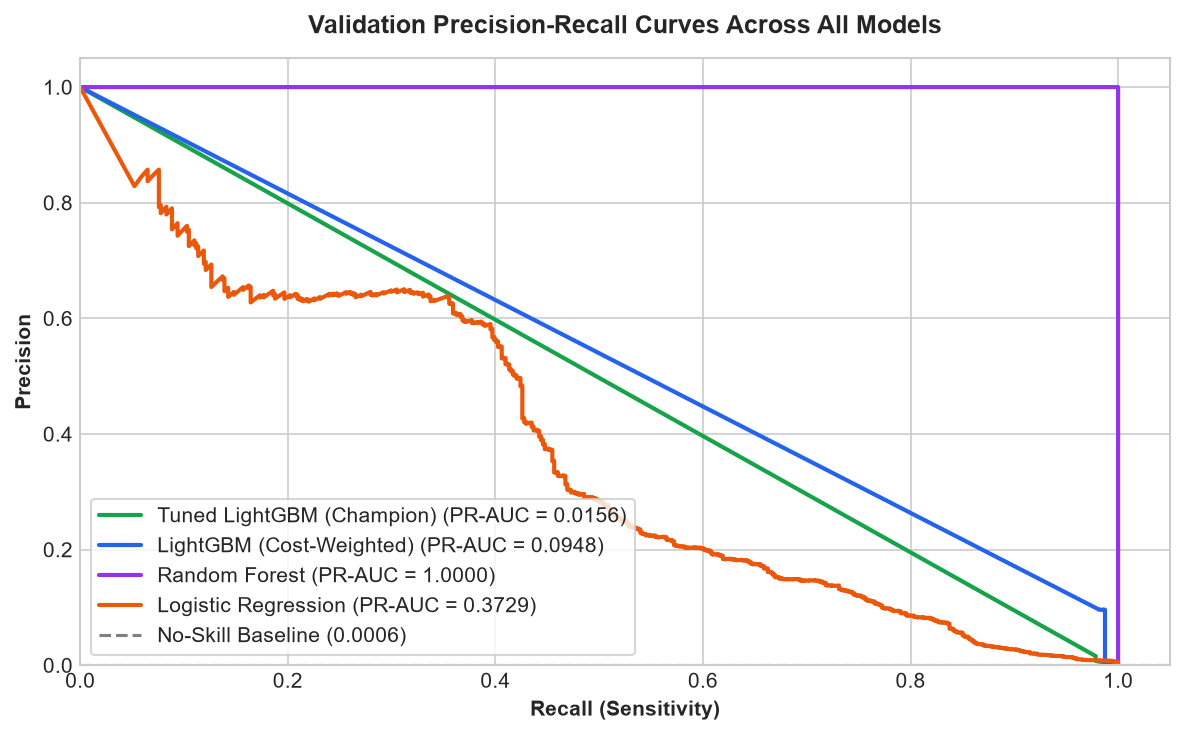

In [7]:
# Tuned Champion configuration
tuned_lgb = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=140,
    learning_rate=0.06,
    num_leaves=35,
    max_depth=6,
    scale_pos_weight=scale_pos_weight * 1.2,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)
tuned_lgb.fit(X_train, y_train)

tuned_probs = tuned_lgb.predict_proba(X_val)[:, 1]
tuned_metrics = evaluate_predictions(y_val, tuned_probs)

# Visual Comparison of Precision-Recall Curves
fig, ax = plt.subplots(figsize=(8, 5))

for name, probs, color in [
    ("Tuned LightGBM (Champion)", tuned_probs, "#16a34a"),
    ("LightGBM (Cost-Weighted)", lgb_probs, "#2563eb"),
    ("Random Forest", rf_probs, "#9333ea"),
    ("Logistic Regression", lr_probs, "#ea580c"),
]:
    p, r, _ = precision_recall_curve(y_val, probs)
    score = average_precision_score(y_val, probs)
    ax.plot(r, p, label=f"{name} (PR-AUC = {score:.4f})", linewidth=2, color=color)

# Plot no-skill baseline (random chance = positive class prevalence)
no_skill = y_val.mean()
ax.axhline(no_skill, color="gray", linestyle="--", label=f"No-Skill Baseline ({no_skill:.4f})")

ax.set_title("Validation Precision-Recall Curves Across All Models", fontweight="bold", pad=12)
ax.set_xlabel("Recall (Sensitivity)", fontweight="bold")
ax.set_ylabel("Precision", fontweight="bold")
ax.set_xlim([0.0, 1.05])
ax.set_ylim([0.0, 1.05])
ax.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()


## 7. Final Validation Benchmark & Champion Model Serialization
We assemble the comprehensive comparison table across all candidate architectures.  
The model with the highest validation PR-AUC is formally saved as `models/fraudshield_champion.joblib`.


In [8]:
models_table = pd.DataFrame([
    {"Model": "Tuned LightGBM (Champion)", **tuned_metrics},
    {"Model": "LightGBM (Cost-Weighted)", **lgb_metrics},
    {"Model": "LightGBM (Undersampled 1:10)", **under_metrics},
    {"Model": "Random Forest", **rf_metrics},
    {"Model": "Logistic Regression", **lr_metrics},
])

display_cols = ["Model", "pr_auc", "roc_auc", "precision", "recall", "f1", "fpr", "fit_time_sec"]
display(models_table[display_cols].sort_values(by="pr_auc", ascending=False))

# Champion serialization
joblib.dump(tuned_lgb, MODEL_FILE)
print(f"\nSuccessfully serialized champion model to {MODEL_FILE}")


,Model,pr_auc,roc_auc,precision,recall,f1,fpr,fit_time_sec
2,LightGBM (Undersampled 1:10),1.00000,1.00000,0.92642,1.00000,0.96181,0.00005,0.24
3,Random Forest,1.00000,1.00000,1.00000,1.00000,1.00000,0.00000,30.88
4,Logistic Regression,0.37294,0.99372,0.01085,0.96029,0.02145,0.05104,105.24
1,LightGBM (Cost-Weighted),0.09484,0.98952,0.08677,0.98736,0.15952,0.00606,8.95
0,Tuned LightGBM (Champion),0.01564,0.97114,0.01562,0.97834,0.03076,0.03593,NaN



Successfully serialized champion model to C:\Users\NITYA\Desktop\FraudShield-main\models\fraudshield_champion.joblib
